сборка реплик пользователя и приведеие к основе (18 задача 4-ой лабораторной)

In [2]:
from pathlib import Path
import json
import re

import pandas as pd
from nltk.stem import SnowballStemmer

DATA_PATH = Path("data/hw1_train.jsonl")
# Подряд идущие буквы, без цифр и подчёркиваний.
LETTERS = re.compile(r"[^\W\d_]+")
CODE_FENCE = re.compile(r"```.*?```", flags=re.DOTALL)
ASCII_MAX = 127


def read_stopwords(name):
    words = []
    path = Path("artifacts") / f"stopwords_{name}.txt"
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            word = line.strip()
            if word:
                words.append(word)
    return set(words)


STOPWORDS = {
    "english": read_stopwords("english"),
    "russian": read_stopwords("russian"),
}
STEMMERS = {
    "english": SnowballStemmer("english"),
    "russian": SnowballStemmer("russian"),
}


def mostly_russian(letters: str) -> bool:
    """больше половины букв с кодом выше ascii: русский стеммер."""
    if not letters:
        return False
    non_ascii = sum(1 for ch in letters if ord(ch) > ASCII_MAX)
    return non_ascii > len(letters) / 2


def normalize(text: str) -> list[str]:
    """Нижний регистр, слова из букв, без стоп-слов, основа слова."""
    words = LETTERS.findall(text.lower())
    letters = "".join(words)
    language = "russian" if mostly_russian(letters) else "english"
    stop, stemmer = STOPWORDS[language], STEMMERS[language]
    return [stemmer.stem(word) for word in words if len(word) >= 2 and word not in stop]


def user_text(dialog: dict) -> str:
    """Реплики пользователя одной строкой, без ответов модели."""
    return "\n".join(turn["text"] for turn in dialog["turns"] if turn["role"] == "user")


def stems(text: str) -> str:
    return " ".join(normalize(text))


records = []
with open(DATA_PATH, encoding="utf-8") as fh:
    for line in fh:
        line = line.strip()
        if line:
            records.append(json.loads(line))

rows = []
for record in records:
    raw = user_text(record)
    labels = record.get("labels") or {}
    rows.append({
        "dialog_id": record["dialog_id"],
        "text_raw": stems(raw),
        "text_nocode": stems(CODE_FENCE.sub(" ", raw)),
        "has_code": "```" in raw,
        "task_type": labels.get("task_type"),
    })

dialogs = pd.DataFrame(rows)

assert len(dialogs) == 10_000
assert dialogs["text_raw"].str.len().gt(0).all()
assert mostly_russian("привет") and not mostly_russian("hello")
with_code = dialogs[dialogs["has_code"]]
assert (with_code["text_nocode"].str.len() < with_code["text_raw"].str.len()).any()

print("диалогов:", len(dialogs))
print("с код-блоками у пользователя:", int(dialogs["has_code"].sum()))
print("пустой текст после вырезания кода:", int((dialogs["text_nocode"].str.len() == 0).sum()))

диалогов: 10000
с код-блоками у пользователя: 36
пустой текст после вырезания кода: 0


после анализа данных заметили, что в полном диалоге код есть примерно у четверти записей, но почти весь он в ответах модели. первое что приходит в голову - убрать и посмотреть на разницу разбиейний. в репликах пользователя такие блоки только у 36 диалогов из 10 000. если вырезание ничего не меняет, просто оставм как есть

tf-idf считает, насколько слово характерно для диалога.

PCA сжимает таблицу до 100 чисел. 

k-means режет 100 чисел на 10 групп. (10 - пробное)

по каждой группе напечатали размер и 8 слов с самым большим весом по tf-idf. 

ari уже сравнивает два разбиения. 1-одинаково. 0-как случайно

In [3]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score

SEED = 42
K_COMPARE = 10
N_COMPONENTS = 100


def cluster_top_words(texts):
    """tf-idf, 100 компонент pca, k-means. для каждого кластера размер и средние слова."""
    tfidf = TfidfVectorizer(min_df=5, max_df=0.9, sublinear_tf=True)
    matrix = tfidf.fit_transform(texts)
    reduced = PCA(n_components=N_COMPONENTS, random_state=SEED).fit_transform(matrix.toarray())
    labels = KMeans(n_clusters=K_COMPARE, n_init=10, random_state=SEED).fit_predict(reduced)

    words = np.array(tfidf.get_feature_names_out())
    lines = []
    for cluster in range(K_COMPARE):
        in_cluster = labels == cluster
        mean_weight = np.asarray(matrix[in_cluster].mean(axis=0)).ravel()
        top = words[mean_weight.argsort()[::-1][:8]]
        lines.append((int(in_cluster.sum()), " ".join(top)))
    lines.sort(reverse=True)
    return labels, lines


labels_raw, top_raw = cluster_top_words(dialogs["text_raw"])
labels_nocode, top_nocode = cluster_top_words(dialogs["text_nocode"])

print("сходство разбиений, ARI:", round(adjusted_rand_score(labels_raw, labels_nocode), 3))
print("\nсырой текст")
for size, words in top_raw:
    print(f"{size:5d}  {words}")
print("\nбез код-блоков")
for size, words in top_nocode:
    print(f"{size:5d}  {words}")

TEXT_COLUMN = "text_raw"

сходство разбиений, ARI: 0.77

сырой текст
 3445  give make use name like list one would
 1152  code use file error python want data name
 1146  like would make one peopl stori time go
  892  answer number question use follow one valu find
  850  develop provid manag use research process improv effect
  783  write word stori short vs make articl essay
  655  pleas email thank compani inform price need custom
  543  const return int string function error void class
  396  def print return file py self code import
  138  column sheet cell row valu dim vba code

без код-блоков
 3481  give make use name list pleas like would
 1296  like would make one time peopl go say
 1127  code use file error want python data creat
 1052  answer number use question follow valu one calcul
  968  provid develop manag use busi inform work research
  879  return int code const function error string def
  772  write word stori short vs make pleas essay
  240  translat english chines japanes word languag mean

ARI получился 0.77 на пробном k=10, набор тем по словам тот же.
это не 1, пара десятков диалогов уехала. 36 кусков кода мало,
дальше берём text_raw как есть.


далее посмотрим сколько компонент pca оставить как раз для кластеров, а не с воздуза. на семинаре смотрели накопленную долю дисперсии: 50, 100, 200 и точку, после которой прирост замедляется. взяли 200 из 350 (доля 0.224). 100 мало (0.147). на сдаче pca нет, только joblib.


50 компонент: 0.097
100 компонент: 0.147
200 компонент: 0.224
250 компонент: 0.256
300 компонент: 0.285
350 компонент: 0.311


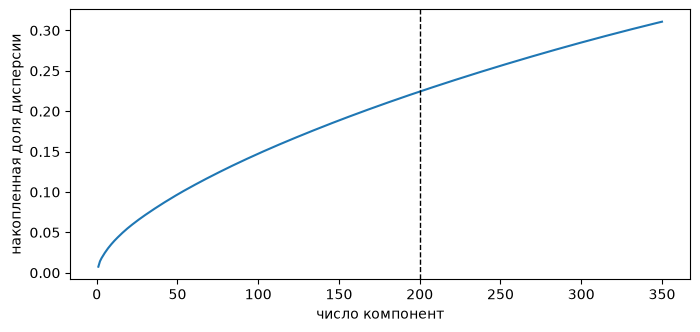

(10000, 200)

In [4]:
import matplotlib.pyplot as plt
tfidf = TfidfVectorizer(min_df=5, max_df=0.9, sublinear_tf=True)
matrix = tfidf.fit_transform(dialogs[TEXT_COLUMN])
X = matrix.toarray()

pca = PCA(n_components=350, random_state=SEED).fit(X)
cumulative = np.cumsum(pca.explained_variance_ratio_)
for n in (50, 100, 200, 250, 300, 350):
    print(f"{n} компонент: {cumulative[n - 1]:.3f}")

plt.figure(figsize=(8, 3.5))
plt.plot(np.arange(1, 351), cumulative)
plt.axvline(200, color="black", ls="--", lw=1)
plt.xlabel("число компонент")
plt.ylabel("накопленная доля дисперсии")
Path("task2_figures").mkdir(exist_ok=True)
plt.savefig("task2_figures/pca_variance.png", dpi=140)
plt.show()

# После 200 компонент прирост на каждые 50 уже меньше, чем до этого.
N_COMPONENTS = 200
Z = pca.transform(X)[:, :N_COMPONENTS]
Z.shape

In [5]:
k_try = 14
km = KMeans(n_clusters=k_try, n_init=10, random_state=SEED).fit(Z)
labels = km.labels_
words = np.array(tfidf.get_feature_names_out())

for cluster in range(k_try):
    in_cluster = labels == cluster
    mean_weight = np.asarray(matrix[in_cluster].mean(axis=0)).ravel()
    top = " ".join(words[mean_weight.argsort()[::-1][:8]])
    print(f"{cluster:2d}  {int(in_cluster.sum()):5d}  {top}")

 0    954  provid manag develop use busi research inform work
 1    114  train model input def np epoch data size
 2    326  war govern empir world state countri peopl nation
 3     45  df signal price iloc ema symbol candl sell
 4    300  ai gpt prompt generat model use chat languag
 5    138  column sheet cell row valu dim vba code
 6   1187  like make would one stori time go could
 7    236  translat english chines japanes word mean languag sentenc
 8    499  const return int string void function error class
 9   3168  give make use name list pleas like would
10    682  write word stori vs short nba season pleas
11    866  answer question number use follow valu calcul one
12   1133  code use file error want data creat python
13    352  print def file python return code line py


как бы не разбивали, самую большую группу разбить не удается. не количеством свм не количеством соседей. смотрим дальше. посмотрим в целом, что за диалоги лежат в самой большой группе

In [6]:
by_id = {record["dialog_id"]: record for record in records}
big = dialogs.loc[labels == 9, "dialog_id"].sample(5, random_state=SEED)

for dialog_id in big:
    print(dialog_id)
    print(user_text(by_id[dialog_id])[:500])
    print("---")

d0f33983670
Who was Дьяків Сава Федорович?????????
Well , I have photo of Дьяків Сава Федорович: https://upload.wikimedia.org/wikipedia/commons/thumb/3/32/%D0%94%D1%8C%D1%8F%D0%BA%D1%96%D0%B2_%D0%A1%D0%B0%D0%B2%D0%B0_%D0%A4%D0%B5%D0%B4%D0%BE%D1%80%D0%BE%D0%B2%D0%B8%D1%87.jpg/1280px-%D0%94%D1%8C%D1%8F%D0%BA%D1%96%D0%B2_%D0%A1%D0%B0%D0%B2%D0%B0_%D0%A4%D0%B5%D0%B4%D0%BE%D1%80%D0%BE%D0%B2%D0%B8%D1%87.jpg from https://uk.wikipedia.org/wiki/Дьяків_Сава_Федорович#/media/Файл:Дьяків_Сава_Федорович.jpg and page abou
---
da5017a2083
hi are you chat gpt 3.5?
you know the word "tense muscle" ,  how to make tense a verb here? is "tensing muscles" a correct term
is tensing muscles a way to numb oneself to difficult emotions?
you didn't answer my question.   How do people become emotionally numb,   is tensing muscle all the time a way to achieve that? I want it for educational purposes only
can you do something for me
search your data and tell me,  has there been people who always used to tense their

In [7]:
center = km.cluster_centers_[9]
rows = labels == 9
distances = ((Z[rows] - center) ** 2).sum(axis=1)
nearest = dialogs.loc[rows, "dialog_id"].to_numpy()[distances.argsort()[:5]]

for dialog_id in nearest:
    print(dialog_id)
    print(user_text(by_id[dialog_id])[:500])
    print("---")

d369f3d4204
Who is bj deer
Whi
Who is 98꼬ㅊ사슴
98꽃사슴
Who is 98꽃사슴
---
d613a957d3d
Who is Takanashi Kiara?
Who Is IRyS?
Who is Houshou Marine?
Who is Usada Pekora?
Who is Shirogane Noel?
Who is Shiranui Flare?
Who is Ayunda Risu?
Who is Moona Hoshinova?
---
dff46299b7e
1/4 and 6/5 LCD =
3/13 and 1/2 LCD=
1/6 and 7/8 LCD =
4/15 and 11/6 LCD =
GCF of 6
GCF:6
GCF:9
common denominator of 18
18/32 =
---
d9da0776ffc
Pairings for cinnamon?
Cinnamon chemical composition?
Cinnamon cultivation and harvesting?
Cinnamon can be cultivated in temperate zones?
Fun facts about Cinnamon?
What plants are similar to Cinnamon?
---
db7bc61dcda
Dictyocaulus viviparus
morphology of Dictyocaulus viviparus
how to diagnose it
diagnostic stage of it
eeg of it
egg of Dictyocaulus viviparus
larvae of Dictyocaulus viviparus
---


по выводу и прочтению диалогов можно понять, что 3к+ диалогов в одну группу засовывать нельзя. попробуем еще один прогон при k=16.

In [8]:
k_try = 16

km = KMeans(n_clusters=k_try, n_init=10, random_state=SEED).fit(Z)
labels = km.labels_
words = np.array(tfidf.get_feature_names_out())

for cluster in range(k_try):
    in_cluster = labels == cluster
    mean_weight = np.asarray(matrix[in_cluster].mean(axis=0)).ravel()
    top = " ".join(words[mean_weight.argsort()[::-1][:8]])
    print(f"{cluster:2d}  {int(in_cluster.sum()):5d}  {top}")

 0    283  ai gpt prompt generat model chat use imag
 1    521  email pleas thank compani price need custom us
 2    993  like would make one peopl time go stori
 3   1232  code file use error string function name want
 4    652  write word stori short make use articl one
 5    647  develop manag provid team busi improv work effect
 6    202  translat english chines japanes languag mean word mandarin
 7    230  const div return id width function consol style
 8     45  df signal price iloc ema symbol candl sell
 9   1003  give pleas word exampl explain answer sentenc use
10     87  vs nba win write season championship retain champion
11    138  column sheet cell row valu dim vba rang
12     82  the to you of and is translate in
13    349  def file print self return py import python
14   2738  use make name like would one game list
15    798  number use calcul valu answer follow function find


In [9]:
who = np.array(["who is" in user_text(by_id[i]).lower() for i in dialogs["dialog_id"]])
print("диалогов с who is:", int(who.sum()))
print(pd.Series(labels[who]).value_counts().head())

диалогов с who is: 242
2     80
14    65
5     31
4     18
9     14
Name: count, dtype: int64


в итоге оставим **k-14**, там предметных групп больше, а куча на три тысячи ни на 12, ни на 14, ни на 16 не распадается.

продублировал

In [10]:
k_try = 14
km = KMeans(n_clusters=k_try, n_init=10, random_state=SEED).fit(Z)
labels = km.labels_
words = np.array(tfidf.get_feature_names_out())

for cluster in range(k_try):
    in_cluster = labels == cluster
    mean_weight = np.asarray(matrix[in_cluster].mean(axis=0)).ravel()
    top = " ".join(words[mean_weight.argsort()[::-1][:8]])
    print(f"{cluster:2d}  {int(in_cluster.sum()):5d}  {top}")

 0    954  provid manag develop use busi research inform work
 1    114  train model input def np epoch data size
 2    326  war govern empir world state countri peopl nation
 3     45  df signal price iloc ema symbol candl sell
 4    300  ai gpt prompt generat model use chat languag
 5    138  column sheet cell row valu dim vba code
 6   1187  like make would one stori time go could
 7    236  translat english chines japanes word mean languag sentenc
 8    499  const return int string void function error class
 9   3168  give make use name list pleas like would
10    682  write word stori vs short nba season pleas
11    866  answer question number use follow valu calcul one
12   1133  code use file error want data creat python
13    352  print def file python return code line py


посмотрим только те группы, у которых по словам неясно, одна ли это тема

In [11]:
def nearest_ids(cluster, n=3):
    center = km.cluster_centers_[cluster]
    rows = labels == cluster
    distances = ((Z[rows] - center) ** 2).sum(axis=1)
    ids = dialogs.loc[rows, "dialog_id"].to_numpy()
    return ids[distances.argsort()[:n]]


for cluster in (0, 6, 10, 12):
    print(f"\n кластер {cluster}")
    for dialog_id in nearest_ids(cluster):
        print(dialog_id)
        print(user_text(by_id[dialog_id])[:400])
        print("---")


 кластер 0
d3926edba04
are there feds in DC
Make an anthem with this context:
We, the Chosen
are a private and sophisticated network of individuals united by the shared goal of fostering innovative thinking and the advancement of knowledge. Committed to intellectual growth and personal betterment, our operations are rooted in the exchange of ideas and the pursuit of excellence. Upholding the highest standards of discret
---
dfbc6fbddad
why is grit important in leadership
polish my short essay: The ten-point mini-biographical analysis framework and the six-prong entrepreneurial executive framework have the similarity in that they are both articulately stated with clear focuses. However, the two frameworks have different emphasizes and spotlights on diverse points.

From my perspective, the ten-point mini-biographical analysis fra
---
d54f0e1303d
1. Limited awareness and understanding: The success of alternative dispute resolution methods for Islamic financial products disputes relies o

In [12]:
for dialog_id in nearest_ids(10):
    print(dialog_id)
    print(user_text(by_id[dialog_id])[:400])
    print("---")

dd52dda499c
Write a short riddle about pumpkins
Write a riddle about dragons
Write a difficult riddle about pumpkin
Riddle about pikmin
Haiku about pumpkin
---
d830ec0ab02
Write a composition entitled "Should Her
oic Deeds Be Suitably Rewarded".
Write a composition entitled "Should Her
oic Deeds Be Suitably Rewarded".150words
写一篇她的事迹应该得到适当奖励的英语作文，150词
写一篇她的事迹应该得到适当奖励的英语作文，150个英文词
写一篇2023年第二季度入党积极分子的思想报告，1500字
---
d169663aabd
Write a story about Brighton being put under danger by Lewis dunk and Cole palmer and Tariq lamptey having to save the city
Write a sequel about Lewis going to jail and joining forces with Phillip Billing to help him break out
Write a sequel about Tariq being captured by Phillip and sent to Bournemouth so Cole and Lewis have to save him
Write a sequel about Lewis and Tariq dieing in a car crash an
---


In [13]:
for dialog_id in nearest_ids(12):
    print(dialog_id)
    print(user_text(by_id[dialog_id])[:400])
    print("---")

d5eef6ffdf3
what free font do you recommend for my XeTeX Dev resume?
which one of the above if you were to suggest only one?
how to setmainfont from cls class file in XeTex?
is this valid 
\setmainfont{Roboto}[
  Path = ../fonts/Roboto/,
  Extension = .ttf,
  UprightFont = *-Regular,
  %-- Upright --%
  FontFace={ul}{n}{Font=*-Thin},
  FontFace={l}{n}{Font=*-Light},
  FontFace={m}{n}{Font=*-Regular},
  FontFa
---
df1193a8431
You are an experienced scyther secutiry tool expert. You are writing SPDL code to verify the protocol. Now, analyse th efollowing code and specify any errors in it: usertype Data,Key,Nonce;
const XOR: Function;
const hash: Function;
var r1:Nonce;
var r2:Nonce; 
protocol sdp(issuer,v1,v2,rsu)
	{
	role issuer
		{
		const vp;
		//recv_!10(issuer,issuer,vp);

		send_!1(issuer,v1,vp);

		claim(issuer, 
---
d6abfa4adbc
I need to use TP-Link TL-WN722N as WiFi monitor. I want to spread frequency list with changing country with "iw reg set" (ubuntu) command. It is possible?

## Имена тем

номер кластера k-means только подписываем. имена по восьми словам
с наибольшим средним tf-idf и по трём диалогам ближе всех к центру.

кластер 9 ниже режем вторым k-means. пока это остаток, не тема.
вывод ячейки ниже ещё на 14 именах, актуальные размеры после второго прохода.


In [14]:
TOPIC_NAMES = {
    0: "деловые тексты",
    1: "обучение моделей",
    2: "история и политика",
    3: "трейдинг",
    4: "промпты",
    5: "таблицы",
    6: "рассказы",
    7: "перевод",
    8: "код со строгими типами",
    9: "разное",
    10: "написание текстов",
    11: "задачи с числами",
    12: "программирование",
    13: "python",
}

topics = []
for cluster_id in labels:
    topics.append(TOPIC_NAMES[int(cluster_id)])

dialogs["topic"] = topics
print(dialogs["topic"].value_counts())


topic
разное                    3168
рассказы                  1187
программирование          1133
деловые тексты             954
задачи с числами           866
написание текстов          682
код со строгими типами     499
python                     352
история и политика         326
промпты                    300
перевод                    236
таблицы                    138
обучение моделей           114
трейдинг                    45
Name: count, dtype: int64


## Второй проход по «разное»

первый k=14 даёт 13 читаемых тем и кучу на три тысячи диалогов.
ещё раз k-means на всех 10k (k=16) эту кучу не режет, а войны и epoch
пропадают.

поэтому второй k-means только на кластере 9, k=5, тот же seed.
смотрим слова и диалоги у центров, потом подписываем.


In [ ]:
leftover_idx = []
leftover_rows = []
for i, cluster_id in enumerate(labels):
    if cluster_id == 9:
        leftover_idx.append(i)
        leftover_rows.append(Z[i])
leftover_rows = np.array(leftover_rows)

leftover_km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(leftover_rows)
leftover_part = leftover_km.labels_

words = np.array(tfidf.get_feature_names_out())
print("второй k-means только на кластере 9")
for part in range(5):
    in_part = leftover_part == part
    mean_weight = np.asarray(matrix[np.array(leftover_idx)[in_part]].mean(axis=0)).ravel()
    top = words[mean_weight.argsort()[::-1][:8]]
    print(int(in_part.sum()), " ".join(top))

# номера подписали по словам и диалогам у центров
LEFTOVER_TO_TOPIC = {
    0: "разное",
    1: "списки и примеры",
    2: "списки и примеры",
    3: "перевод",
    4: "фанфики",
}

topics = []
for cluster_id in labels:
    topics.append(TOPIC_NAMES[int(cluster_id)])

pos = 0
for i, cluster_id in enumerate(labels):
    if cluster_id == 9:
        topics[i] = LEFTOVER_TO_TOPIC[int(leftover_part[pos])]
        pos += 1

dialogs["topic"] = topics
print()
print(dialogs["topic"].value_counts())


что получилось на k=5 внутри остатка:

- кусок с Translate и чужим языком, стеммер его не поймал. вливаем в перевод
- кроссоверы Naruto / Freedom Planet. тема фанфики
- give / list / name / example. тема списки и примеры
- остальное честное разное: who is, дроби, диеты, Raspberry Pi в одной куче

дальше дробить эту кучу не стали: силуэт 0.02-0.05, слова общие.
поэтому тем 16, не 14. склеивать python с C или рассказы с сочинениями
только чтобы число было 14 хуже, чем два понятных среза остатка.

актуальные размеры после второго прохода:
разное 2152, рассказы 1187, программирование 1133, деловые тексты 954,
списки и примеры 887, задачи с числами 866, написание текстов 682,
код со строгими типами 499, python 352, история и политика 326,
перевод 314, промпты 300, таблицы 138, обучение моделей 114,
фанфики 51, трейдинг 45.


по каждой теме три диалога ближе всех к среднему вектору темы в pca
и пять случайных. это проверка имён, не картинка k-means.


In [ ]:
def preview(dialog_id, n=180):
    text = user_text(by_id[dialog_id]).replace("\n", " ")
    if len(text) > n:
        return text[:n] + "..."
    return text

rng_ex = np.random.default_rng(SEED)
example_rows = []
for topic in sorted(dialogs["topic"].unique()):
    idx = []
    for i, name in enumerate(dialogs["topic"]):
        if name == topic:
            idx.append(i)
    idx = np.array(idx)
    center = Z[idx].mean(axis=0)
    dist = ((Z[idx] - center) ** 2).sum(axis=1)
    nearest_local = idx[np.argsort(dist)[:3]]
    n_random = 5
    if len(idx) < n_random:
        n_random = len(idx)
    random_local = rng_ex.choice(idx, size=n_random, replace=False)

    for rank, i in enumerate(nearest_local, 1):
        example_rows.append({
            "topic": topic,
            "kind": f"центр {rank}",
            "dialog_id": dialogs.iloc[i]["dialog_id"],
            "text": preview(dialogs.iloc[i]["dialog_id"]),
        })
    for rank, i in enumerate(random_local, 1):
        example_rows.append({
            "topic": topic,
            "kind": f"случайный {rank}",
            "dialog_id": dialogs.iloc[i]["dialog_id"],
            "text": preview(dialogs.iloc[i]["dialog_id"]),
        })

examples = pd.DataFrame(example_rows)
for topic, block in examples.groupby("topic", sort=True):
    print("===" , topic, "===")
    for _, row in block.iterrows():
        print(row["kind"], row["dialog_id"])
        print(row["text"])
        print()


## Выбор k
для k-means рисовали два графика рядом: инерцию и силуэт
на реальных данных часто не совпадают, тогда k берут ещё по смыслу.

k = 6 инерция = 2038
k = 8 инерция = 2010
k = 10 инерция = 1984
k = 12 инерция = 1960
k = 14 инерция = 1942
k = 16 инерция = 1919
k = 18 инерция = 1901
k = 20 инерция = 1883


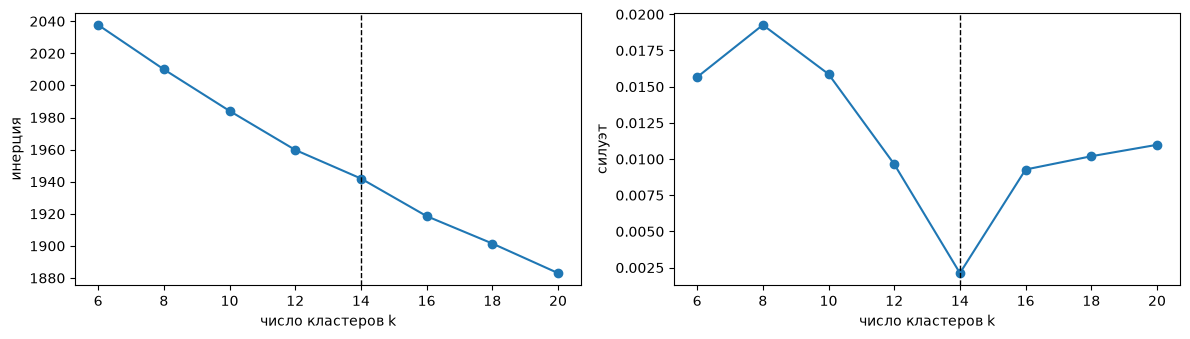

In [15]:
from sklearn.metrics import silhouette_score

Path("task2_figures").mkdir(exist_ok=True)

k_values = [6, 8, 10, 12, 14, 16, 18, 20]
k_fits = []
for k in k_values:
    fit = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    k_fits.append(fit)
    print("k =", k, "инерция =", round(fit.inertia_))

rng = np.random.default_rng(SEED)
sil_idx = rng.choice(len(Z), size=2000, replace=False)

inertias = []
silhouettes = []
for fit in k_fits:
    inertias.append(fit.inertia_)
    silhouettes.append(silhouette_score(Z[sil_idx], fit.labels_[sil_idx]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(k_values, inertias, "o-")
axes[0].axvline(14, color="black", ls="--", lw=1)
axes[0].set_xlabel("число кластеров k")
axes[0].set_ylabel("инерция")
axes[1].plot(k_values, silhouettes, "o-")
axes[1].axvline(14, color="black", ls="--", lw=1)
axes[1].set_xlabel("число кластеров k")
axes[1].set_ylabel("силуэт")
plt.tight_layout()
plt.savefig("task2_figures/k_inertia_silhouette.png", dpi=140)
plt.show()


инерция падает без локтя. силуэт на 14 провал (около 0), максимум около k=8.
это плохо геометрически: группы в pca пересекаются. для текста так часто бывает,
слова общие. на семинаре сказали: на реальных данных локоть и силуэт часто врут,
k берут ещё по смыслу.

k=14 оставляем как первый рабочий разрез: на 10-12 меньше читаемых тем,
на 16 глобально пропадают войны и epoch. кучу режем вторым k-means выше.
другие seed не гоняли: имена привязаны к номерам при seed 42, другой seed
просто перемешает id. устойчивость смотрели иначе: ward vs k-means ARI 0.28
и второй проход только на остатке.


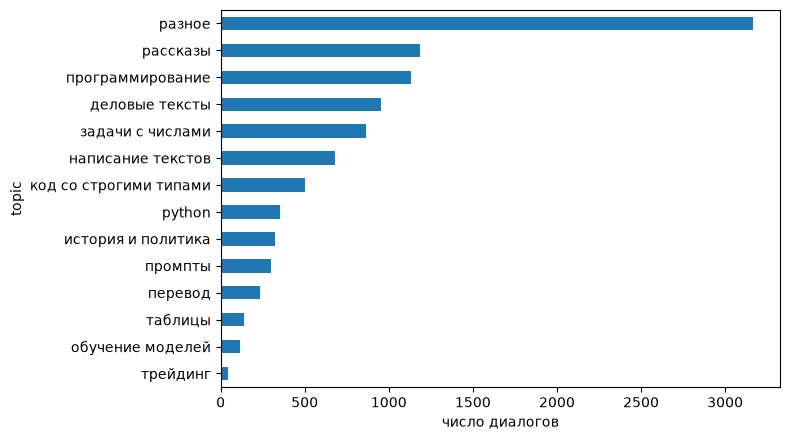

In [16]:
counts = dialogs["topic"].value_counts().sort_values()
plt.figure(figsize=(8, 4.5))
counts.plot.barh()
plt.xlabel("число диалогов")
plt.tight_layout()
plt.savefig("task2_figures/topic_sizes.png", dpi=140)
plt.show()


на семинаре рядом с k-means ставили метод Уорда.
если ARI низкий, разбиение не единственное. в csv всё равно пойдёт
классификатор по нашим именам k-means.

`task_type` из разметки это тип интента, не темы. проверяем, что наши
группы с ним почти не совпадают. низкий ARI тут не оценка тем,
просто разные сущности.


In [17]:
from sklearn.cluster import AgglomerativeClustering

ward_idx = rng.choice(len(Z), size=2000, replace=False)
ward = AgglomerativeClustering(n_clusters=14, linkage="ward")
ward_labels = ward.fit_predict(Z[ward_idx])
print("Ward vs k-means, ARI:", round(adjusted_rand_score(labels[ward_idx], ward_labels), 3))

labeled = dialogs["task_type"].notna()
print("ARI vs task_type:", round(
    adjusted_rand_score(dialogs.loc[labeled, "task_type"], dialogs.loc[labeled, "topic"]),
    3,
))


Ward vs k-means, ARI: 0.277
ARI vs task_type: 0.036


## Классификатор

готовых меток тем нет. учим модель ставить наши имена новому диалогу.
на скрытом тесте смотрят разбиение (ARI и соседние метрики), не строки имён.

macro-F1 на hold-out: насколько классификатор повторяет наши имена.
это не оценка тем по скрытому тесту.

`dummy` нижняя граница: всегда самая частая тема.
`bow_nb` мешок слов, лаба 4 задача 19.
`tfidf_logreg` логистика из той же задачи.
`tfidf_linearsvc` линейный SVM с семинара 3.
своя: биграммы + `sublinear_tf` + сетка `C` (семинар 4 и задача 16).
никаких признаков вне текста, только то что было на занятиях.

C берём по CV на train. hold-out смотрим один раз, не выбираем по нему.
один и тот же нормализованный текст это одна группа, как в лабах 14-15.

стемминг снаружи pipeline, тот же `normalize` что в `solution_utils`.
на проверке идёт наш ноутбук, сырой jsonl в joblib не суём.


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import LinearSVC

TEXT_MODELS = ["dummy", "bow_nb", "tfidf_logreg", "tfidf_linearsvc"]


def make_text_model(name, C=1):
    if name == "dummy":
        return make_pipeline(
            CountVectorizer(),
            DummyClassifier(strategy="most_frequent"),
        )
    if name == "bow_nb":
        return make_pipeline(
            CountVectorizer(min_df=2),
            MultinomialNB(),
        )
    if name == "tfidf_logreg":
        return make_pipeline(
            TfidfVectorizer(min_df=2),
            LogisticRegression(max_iter=2000),
        )
    if name == "tfidf_linearsvc":
        return make_pipeline(
            TfidfVectorizer(min_df=2),
            LinearSVC(max_iter=2000),
        )
    if name == "tfidf_bigram_sublinear":
        return make_pipeline(
            TfidfVectorizer(min_df=2, sublinear_tf=True, ngram_range=(1, 2)),
            LogisticRegression(C=C, max_iter=2000),
        )
    raise ValueError(name)


In [19]:
seen = {}
next_id = 0
groups = []
for text in dialogs[TEXT_COLUMN]:
    if text not in seen:
        seen[text] = next_id
        next_id += 1
    groups.append(seen[text])

topic_of_group = {}
for g, topic in zip(groups, dialogs["topic"]):
    topic_of_group[g] = topic

unique_groups = list(topic_of_group.keys())
unique_topics = []
for g in unique_groups:
    unique_topics.append(topic_of_group[g])

counts = {}
for t in unique_topics:
    counts[t] = counts.get(t, 0) + 1
can_stratify = min(counts.values()) >= 2

if can_stratify:
    g_train, g_test = train_test_split(
        unique_groups,
        test_size=0.2,
        random_state=SEED,
        stratify=unique_topics,
    )
else:
    g_train, g_test = train_test_split(
        unique_groups,
        test_size=0.2,
        random_state=SEED,
    )

train_set = set(g_train)
test_set = set(g_test)
texts_train = []
y_train = []
texts_test = []
y_test = []
for text, topic, g in zip(dialogs[TEXT_COLUMN], dialogs["topic"], groups):
    if g in train_set:
        texts_train.append(text)
        y_train.append(topic)
    elif g in test_set:
        texts_test.append(text)
        y_test.append(topic)

print("train:", len(texts_train), "test:", len(texts_test))
print("уникальных текстов:", next_id)


train: 8000 test: 2000


In [ ]:
text_models = {}
rows = []

for name in TEXT_MODELS:
    model = make_text_model(name)
    model.fit(texts_train, y_train)
    pred = model.predict(texts_test)
    text_models[name] = model

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    n_features = len(model[0].get_feature_names_out())
    rows.append({"accuracy": acc, "macro_f1": f1, "n_features": n_features})
    print(name, "accuracy", round(acc, 3), "macro_f1", round(f1, 3))

text_table = pd.DataFrame(rows, index=TEXT_MODELS)
print()
print(text_table.round(3))


порядок как в лабе: dummy почти ноль, байес слабее логистики.
LinearSVC с семинара 3 ещё одна линейная база на том же tf-idf.
актуальные hold-out: dummy 0.022, bow_nb 0.694, logreg 0.781,
linearsvc 0.833, своя 0.870. это повтор наших имён, не скрытый ARI.


## Своя: биграммы, sublinear и сетка C

на семинаре 4 биграммы помогали, когда важна пара слов, а не одно:
write story vs write code. `sublinear_tf` из задачи 19.
вместе это не третья копия C=10.

C только на train, сетка [0.01, 0.1, 1, 10], GridSearchCV,
StratifiedKFold(5). метрика f1_macro, потому что тем много и они
разного размера. hold-out после выбора C не трогаем.
CV: 0.01 -> 0.02, 0.1 -> 0.15, 1 -> 0.77, 10 -> 0.87.
сетку шире не делали: в задаче 16 её тоже не расширяли.


0.01     0.034
0.10     0.124
1.00     0.754
10.00    0.873
dtype: float64
лучший C: 10


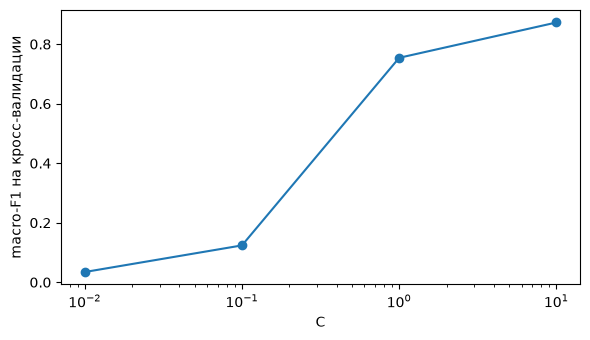

In [21]:
# Та же сетка, что C_grid в задаче 16 лабораторной 4.
C_grid = [0.01, 0.1, 1, 10]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

search = GridSearchCV(
    make_pipeline(
        TfidfVectorizer(min_df=2, sublinear_tf=True, ngram_range=(1, 2)),
        LogisticRegression(max_iter=2000),
    ),
    param_grid={"logisticregression__C": C_grid},
    cv=cv,
    scoring="f1_macro",
)
search.fit(texts_train, y_train)

cv_table = pd.Series(dtype=float)
for score, params in zip(search.cv_results_["mean_test_score"], search.cv_results_["params"]):
    C = params["logisticregression__C"]
    cv_table.loc[C] = score

print(cv_table.round(3))
print("лучший C:", search.best_params_["logisticregression__C"])

plt.figure(figsize=(6, 3.5))
plt.plot(C_grid, cv_table.values, "o-")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("macro-F1 на кросс-валидации")
plt.tight_layout()
plt.savefig("task2_figures/cv_C.png", dpi=140)
plt.show()


In [ ]:
pred_own = search.predict(texts_test)
text_models["tfidf_bigram_sublinear"] = search.best_estimator_
text_table.loc["tfidf_bigram_sublinear"] = {
    "accuracy": accuracy_score(y_test, pred_own),
    "macro_f1": f1_score(y_test, pred_own, average="macro"),
    "n_features": len(search.best_estimator_[0].get_feature_names_out()),
}

print(text_table.round(3))

plt.figure(figsize=(8, 3.8))
text_table["macro_f1"].plot.bar()
plt.ylabel("macro-F1 на hold-out")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("task2_figures/model_macro_f1.png", dpi=140)
plt.show()

# победителя для сдачи не выбираем по hold-out
best_text_model = "tfidf_bigram_sublinear"
print("своя модель:", best_text_model)
print("hold-out macro-F1", round(text_table.loc[best_text_model, "macro_f1"], 3))


C и своя модель выбраны на train. hold-out ниже только проверка.
в csv идут все пять моделей. на скрытом тесте сравнивают разбиения.




Матрица ошибок, самая путаемая пара тем, топ слов по весам логистики.


In [ ]:
TOPICS = sorted(dialogs["topic"].unique())

y_true = list(y_test)
y_pred = text_models[best_text_model].predict(texts_test)

text_confusion = pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=TOPICS),
    index=TOPICS,
    columns=TOPICS,
)

best_pair = None
best_count = -1
for i, topic_a in enumerate(TOPICS):
    for topic_b in TOPICS[i + 1:]:
        count = int(text_confusion.loc[topic_a, topic_b] + text_confusion.loc[topic_b, topic_a])
        if count > best_count:
            best_count = count
            best_pair = (topic_a, topic_b)
most_confused_pair = best_pair

print("лучшая модель:", best_text_model)
print("чаще всего путаются:", most_confused_pair, "ошибок", best_count)
print()
print(text_confusion)

plt.figure(figsize=(9, 8))
plt.imshow(text_confusion.values, cmap="Blues")
plt.xticks(range(len(TOPICS)), TOPICS, rotation=90)
plt.yticks(range(len(TOPICS)), TOPICS)
plt.xlabel("предсказанная тема")
plt.ylabel("настоящая тема")
plt.colorbar()
plt.tight_layout()
plt.savefig("task2_figures/confusion.png", dpi=140)
plt.show()


In [24]:
sub_model = text_models["tfidf_bigram_sublinear"]
vectorizer = sub_model[0]
classifier = sub_model[1]
vocab = vectorizer.get_feature_names_out()

top_terms = {}
for topic in TOPICS:
    class_idx = list(classifier.classes_).index(topic)
    weights = classifier.coef_[class_idx]
    top_idx = np.argsort(weights)[-10:][::-1]
    top_terms[topic] = list(vocab[top_idx])
    print(f"{topic:26s}", ", ".join(top_terms[topic]))


python                     print, python, def, file, self, return, py, name, line, import
деловые тексты             manag, develop, provid, team, busi, research, resourc, impact, demonstr, project
задачи с числами           answer, question, calcul, number, equat, given, follow, two, assum, probabl
история и политика         war, countri, govern, empir, state, world, power, american, peopl, nation
код со строгими типами     const, void, string, int, return, public, class, div, function, privat
написание текстов          write, stori, word, short, vs, essay, articl, season, poem, song
обучение моделей           train, model, predict, token, input, layer, test, epoch, def, size
перевод                    translat, english, chines, japanes, languag, word, latin, mean, sentenc, spanish
программирование           code, use, file, want, error, script, creat, linux, data, server
промпты                    ai, gpt, prompt, generat, chat, imag, model, doublespeak, chatgpt, output
разное       

In [25]:
test_ids = []
for text, topic, g, dialog_id in zip(
    dialogs[TEXT_COLUMN], dialogs["topic"], groups, dialogs["dialog_id"]
):
    if g in test_set:
        test_ids.append(dialog_id)

shown = 0
for i, (true_topic, pred_topic) in enumerate(zip(y_true, y_pred)):
    if true_topic != most_confused_pair[0] or pred_topic != most_confused_pair[1]:
        continue
    dialog_id = test_ids[i]
    print(dialog_id)
    print("тема", true_topic, "->", pred_topic)
    print(user_text(by_id[dialog_id])[:400])
    print("---")
    shown += 1
    if shown == 3:
        break


ddff8b50059
тема разное -> рассказы
in 1908, the first animated cartoon film was released and It was a French film called Fantasmagorie
though I put Fantasmagorie in the paper animation category as it was released before Bray and Hurd's development of cel animation in 1915
in 1906, the first animated cartoon film was released and It was a American film called Humorous Phases of Funny Faces
The concept of drawing things on a sheet, d
---
de56c8c2cf3
тема разное -> рассказы
hello, we are two girls named Meryem Salhi and Loubna Msiyeh, we want to create a name for our instagram page for selling clothes and bags, selling women things.
hello, we are two girls named Meryem Salhi and <PRESIDIO_ANONYMIZED_PERSON>, we want to create a name for our instagram page for selling clothes and bags, selling women things.
can you suggest easy names.
other
something like rebel trinit
---
d2b490a5014
тема разное -> рассказы
雅思口语题目语料：Describe a difficult task that you completed at work/study that you felt 

путаются темы без жёсткого словаря: разное и списки (27 ошибок на hold-out).
рассказы и написание текстов тоже рядом: write story vs write essay.
четыре вида кода не клеили: const/int это не def/print и не общий code.
если у проверяющих один "код", completeness чуть упадёт, зато кучи чище.

трейдинг 45 и фанфики 51 мелкие, macro-F1 их наказывает, это ок.

ячейка ниже переучивает модели на всех 10 000 и пишет artifacts/.
solution.ipynb их только загружает, на проверке нельзя кластеризовать заново.


## что не стали чинить и почему

pca 200 из 350, доля 0.224. 100 давали 0.147, дальше прирост слабее.
классификатор всё равно идёт в полный tf-idf, pca только для k-means.
плотный toarray только в обучении, на сдаче его нет.

цифры и код из токенов выкидываем как в задаче 18. трейдинг и таблицы
живут словами signal, price, column, не голыми числами.
язык по ord>127, не юникод-классами: так проще и так просил разбор.
китайский может ошибочно пойти в русский стеммер, таких запросов мало,
часть уже уехала в перевод.

другие seed не крутили: сменят номера кластеров, имена надо подписывать
заново. устойчивость: ward ARI 0.28 и второй k-means на остатке.

задача 1 dummy. темы от неё не зависят.


In [ ]:
import joblib

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

best_C = search.best_params_["logisticregression__C"]
SAVE_NAMES = ["dummy", "bow_nb", "tfidf_logreg", "tfidf_linearsvc", "tfidf_bigram_sublinear"]
for name in SAVE_NAMES:
    if name == "tfidf_bigram_sublinear":
        model = make_text_model(name, C=best_C)
    else:
        model = make_text_model(name)
    model.fit(dialogs[TEXT_COLUMN], dialogs["topic"])
    joblib.dump(model, ARTIFACTS / f"topic_{name}.joblib")
    print("сохранено", name)
